# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Unit Square Packing Bounds Dataset](https://www.kaggle.com/datasets/pablodiegoo/unit-square-packing-certified-bounds?select=unit_square_packing_bounds_n1_to_1000.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('unit_square_packing_bounds_n1_to_1000.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,n,k_shell,shell_remainder_d,grid_ceiling_side,certified_side_length,area_lower_bound_sqrt_n,excess_score_contribution,side_saving_vs_grid,wasted_area,grid_wasted_area,tilted_square_count,tilted_fraction,max_tilt_angle_deg,geometric_regime
0,1,1,0,1,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0,0,0.0,0.0,exact_orthogonal_grid
1,2,1,1,2,2.000000,1.414214,4.142136e-01,0.000000,2.000000,2,0,0.0,0.0,exact_orthogonal_grid
2,3,1,2,2,2.000000,1.732051,1.547005e-01,0.000000,1.000000,1,0,0.0,0.0,exact_orthogonal_grid
3,4,2,0,2,2.000000,2.000000,5.000000e-12,0.000000,0.000000,0,0,0.0,0.0,exact_orthogonal_grid
4,5,2,1,3,2.707107,2.236068,2.106550e-01,0.292893,2.328427,4,1,0.2,45.0,comb_shear_or_fault_line


## last Five row

In [4]:
df.tail()

,n,k_shell,shell_remainder_d,grid_ceiling_side,certified_side_length,area_lower_bound_sqrt_n,excess_score_contribution,side_saving_vs_grid,wasted_area,grid_wasted_area,tilted_square_count,tilted_fraction,max_tilt_angle_deg,geometric_regime
995,996,31,35,32,31.959463,31.559468,0.012674,0.040537,25.407252,28,353,0.3544,17.9076,erdos_graham_l_band_or_quench
996,997,31,36,32,31.979832,31.575307,0.012811,0.020168,25.709634,27,370,0.3711,20.0040,erdos_graham_l_band_or_quench
997,998,31,37,32,31.992627,31.591138,0.012709,0.007373,25.528173,26,315,0.3156,28.7385,erdos_graham_l_band_or_quench
998,999,31,38,32,32.000000,31.606961,0.012435,0.000000,25.000000,25,0,0.0000,0.0000,exact_orthogonal_grid
999,1000,31,39,32,32.000000,31.622777,0.011929,0.000000,24.000000,24,0,0.0000,0.0000,exact_orthogonal_grid


## Shape of our dataset

In [5]:
df.shape

(1000, 14)

## List out all columns

In [6]:
df.columns

Index(['n', 'k_shell', 'shell_remainder_d', 'grid_ceiling_side',
       'certified_side_length', 'area_lower_bound_sqrt_n',
       'excess_score_contribution', 'side_saving_vs_grid', 'wasted_area',
       'grid_wasted_area', 'tilted_square_count', 'tilted_fraction',
       'max_tilt_angle_deg', 'geometric_regime'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

n                              int64
k_shell                        int64
shell_remainder_d              int64
grid_ceiling_side              int64
certified_side_length        float64
area_lower_bound_sqrt_n      float64
excess_score_contribution    float64
side_saving_vs_grid          float64
wasted_area                  float64
grid_wasted_area               int64
tilted_square_count            int64
tilted_fraction              float64
max_tilt_angle_deg           float64
geometric_regime              object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   n                          1000 non-null   int64  
 1   k_shell                    1000 non-null   int64  
 2   shell_remainder_d          1000 non-null   int64  
 3   grid_ceiling_side          1000 non-null   int64  
 4   certified_side_length      1000 non-null   float64
 5   area_lower_bound_sqrt_n    1000 non-null   float64
 6   excess_score_contribution  1000 non-null   float64
 7   side_saving_vs_grid        1000 non-null   float64
 8   wasted_area                1000 non-null   float64
 9   grid_wasted_area           1000 non-null   int64  
 10  tilted_square_count        1000 non-null   int64  
 11  tilted_fraction            1000 non-null   float64
 12  max_tilt_angle_deg         1000 non-null   float64
 13  geometric_regime           1000 non-null   object

## Check Null Value

In [9]:
df.isnull().sum()

n                            0
k_shell                      0
shell_remainder_d            0
grid_ceiling_side            0
certified_side_length        0
area_lower_bound_sqrt_n      0
excess_score_contribution    0
side_saving_vs_grid          0
wasted_area                  0
grid_wasted_area             0
tilted_square_count          0
tilted_fraction              0
max_tilt_angle_deg           0
geometric_regime             0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,n,k_shell,shell_remainder_d,grid_ceiling_side,certified_side_length,area_lower_bound_sqrt_n,excess_score_contribution,side_saving_vs_grid,wasted_area,grid_wasted_area,tilted_square_count,tilted_fraction,max_tilt_angle_deg
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,20.615000,20.155000,21.584000,21.462823,21.097456,0.022223,0.121177,15.582884,21.052000,96.084000,0.173734,18.978169
std,288.819436,7.444609,14.497971,7.465834,7.448866,7.446664,0.024814,0.151162,9.051183,15.157805,128.453381,0.183254,18.308080
min,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,250.750000,15.000000,8.000000,16.000000,16.000000,15.835082,0.011431,0.000000,8.000000,8.000000,0.000000,0.000000,0.000000
50%,500.500000,22.000000,18.000000,23.000000,22.855921,22.371855,0.017512,0.033832,16.000000,19.000000,25.000000,0.111750,22.763700
75%,750.250000,27.000000,30.000000,28.000000,27.861345,27.390691,0.025250,0.221825,23.493127,32.000000,169.500000,0.349300,34.744575
max,1000.000000,31.000000,60.000000,32.000000,32.000000,31.622777,0.414214,0.479185,32.545094,62.000000,625.000000,0.836700,45.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

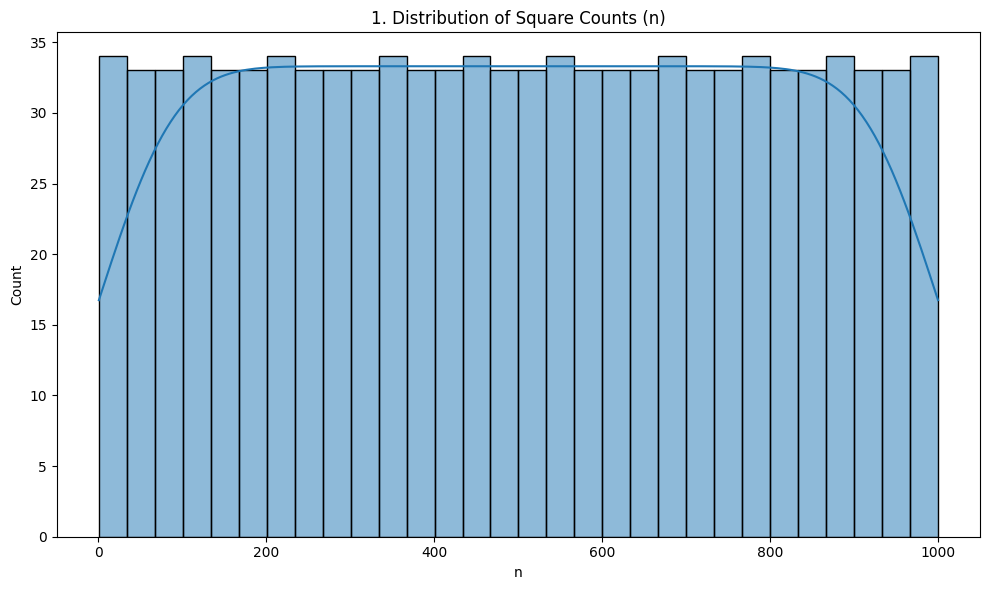

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='n', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Square Counts (n)')
show_fig()
plot_no += 1

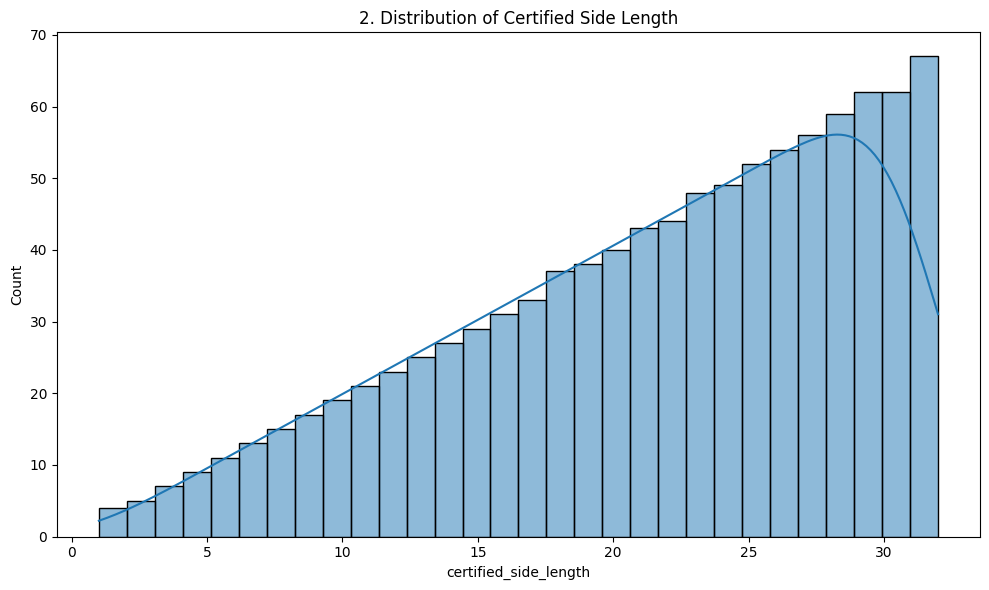

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='certified_side_length', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Certified Side Length')
show_fig()
plot_no += 1

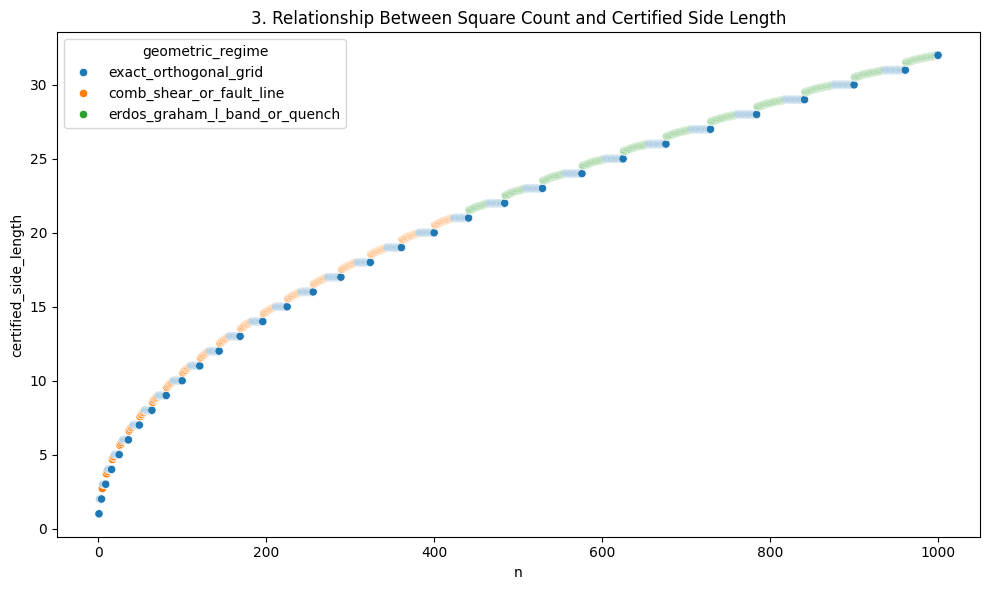

In [15]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='n', y='certified_side_length', hue='geometric_regime')
plt.title(f'{plot_no}. Relationship Between Square Count and Certified Side Length')
show_fig()
plot_no += 1

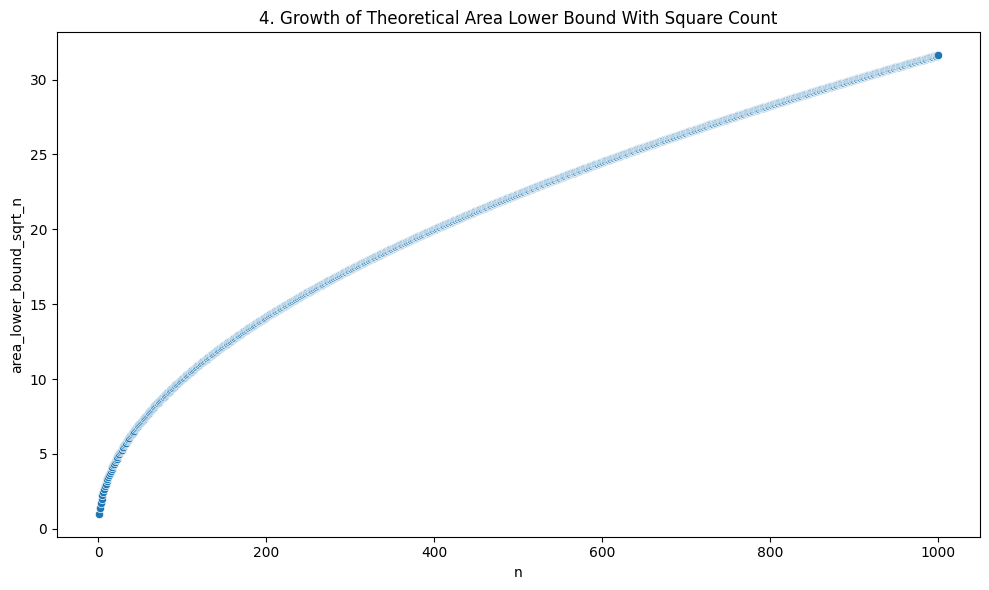

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='n', y='area_lower_bound_sqrt_n')
plt.title(f'{plot_no}. Growth of Theoretical Area Lower Bound With Square Count')
show_fig()
plot_no += 1

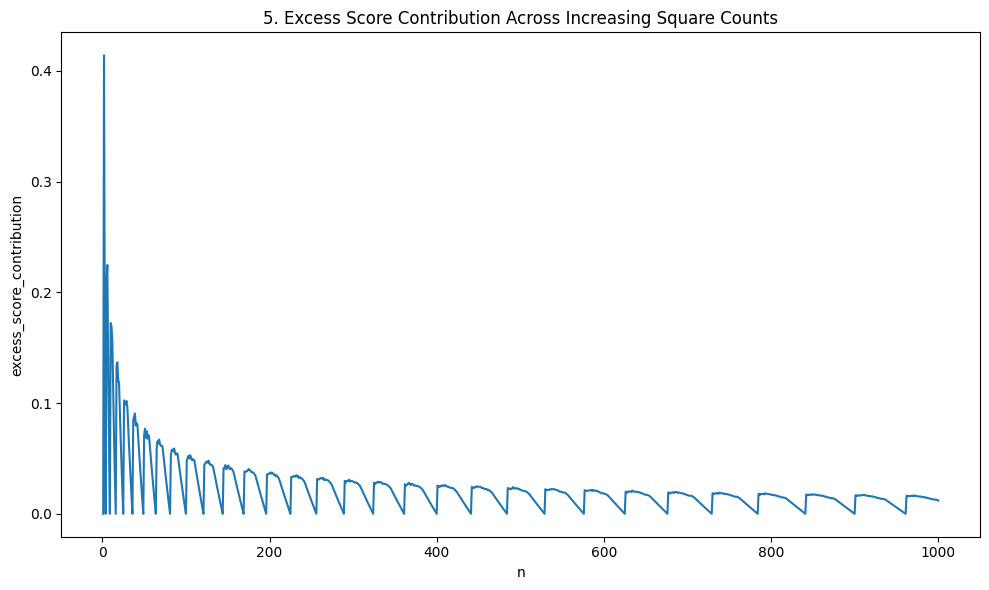

In [17]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='n', y='excess_score_contribution')
plt.title(f'{plot_no}. Excess Score Contribution Across Increasing Square Counts')
show_fig()
plot_no += 1

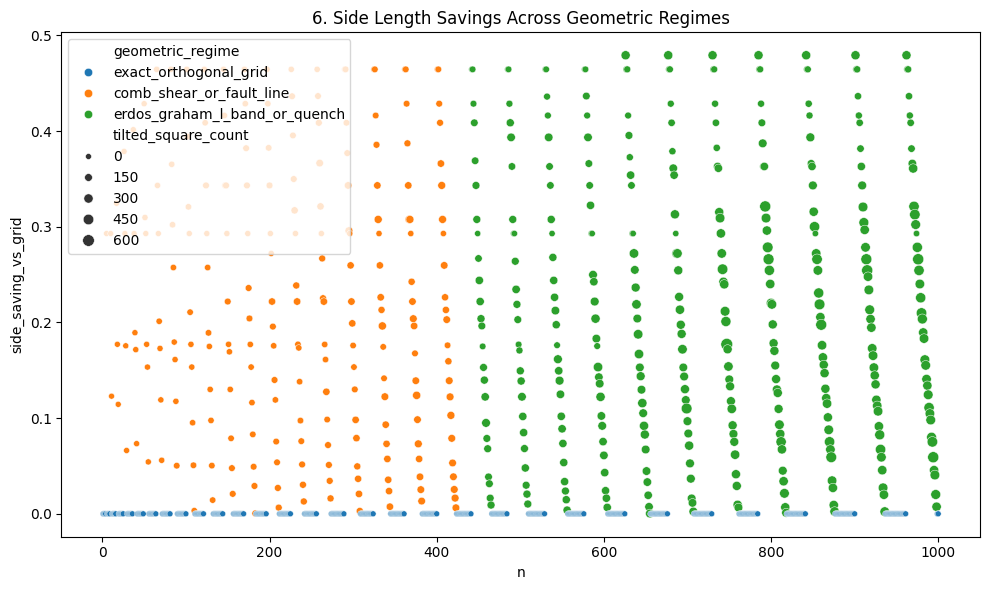

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='n', y='side_saving_vs_grid', hue='geometric_regime', size='tilted_square_count')
plt.title(f'{plot_no}. Side Length Savings Across Geometric Regimes')
show_fig()
plot_no += 1

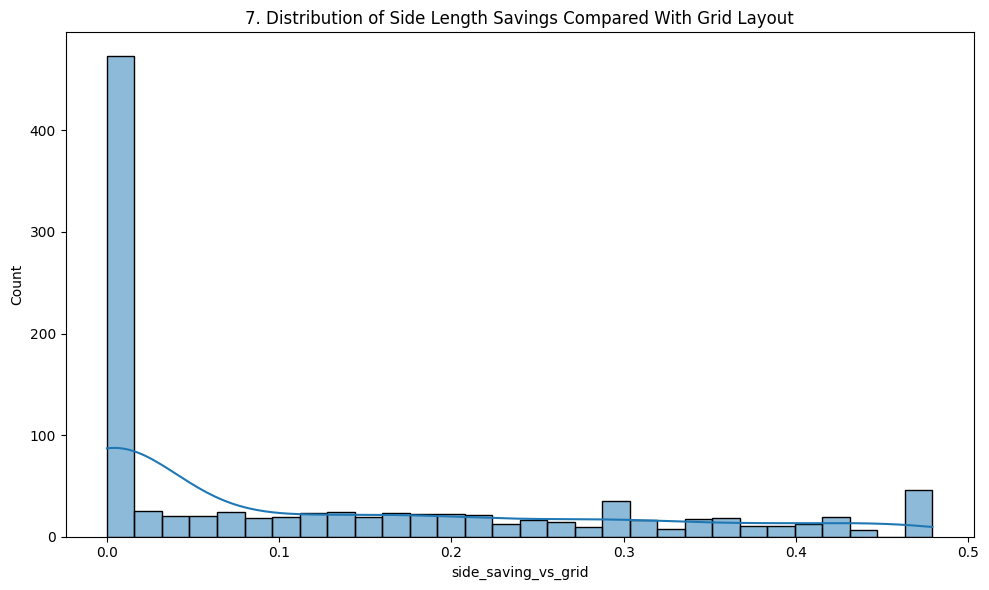

In [19]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='side_saving_vs_grid', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Side Length Savings Compared With Grid Layout')
show_fig()
plot_no += 1

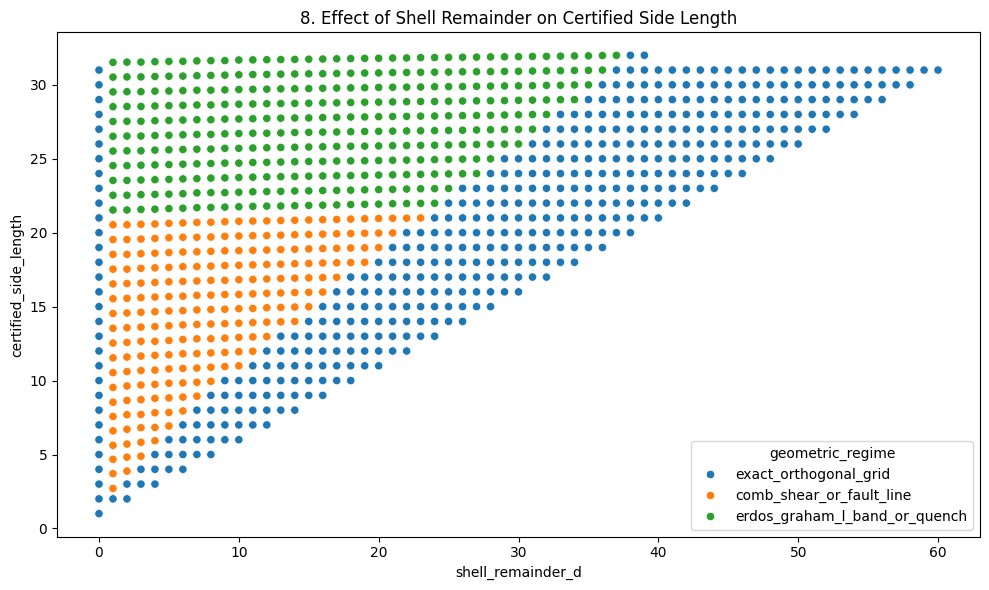

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='shell_remainder_d', y='certified_side_length', hue='geometric_regime')
plt.title(f'{plot_no}. Effect of Shell Remainder on Certified Side Length')
show_fig()
plot_no += 1

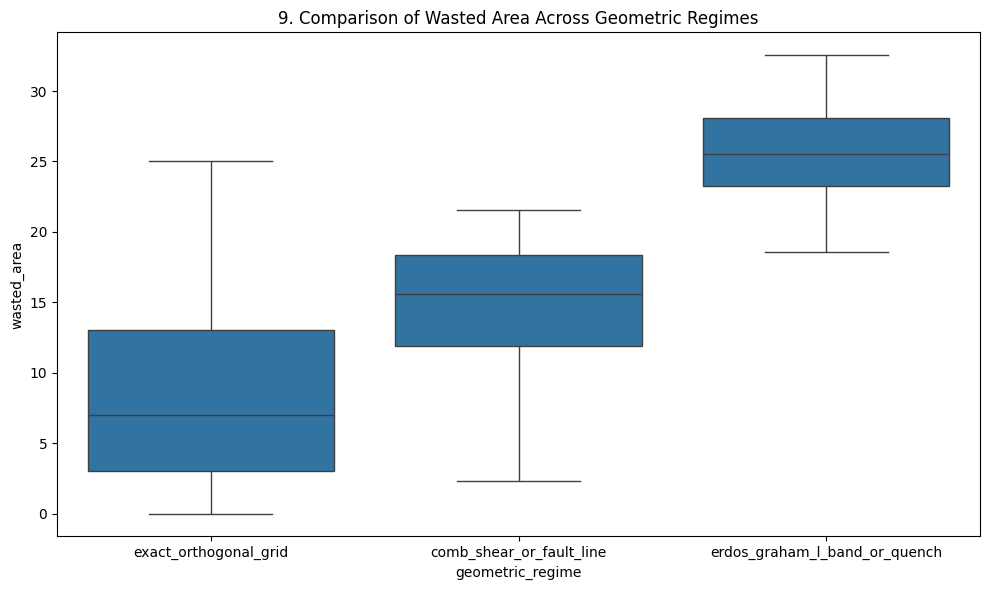

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='geometric_regime', y='wasted_area')
plt.title(f'{plot_no}. Comparison of Wasted Area Across Geometric Regimes')
show_fig()

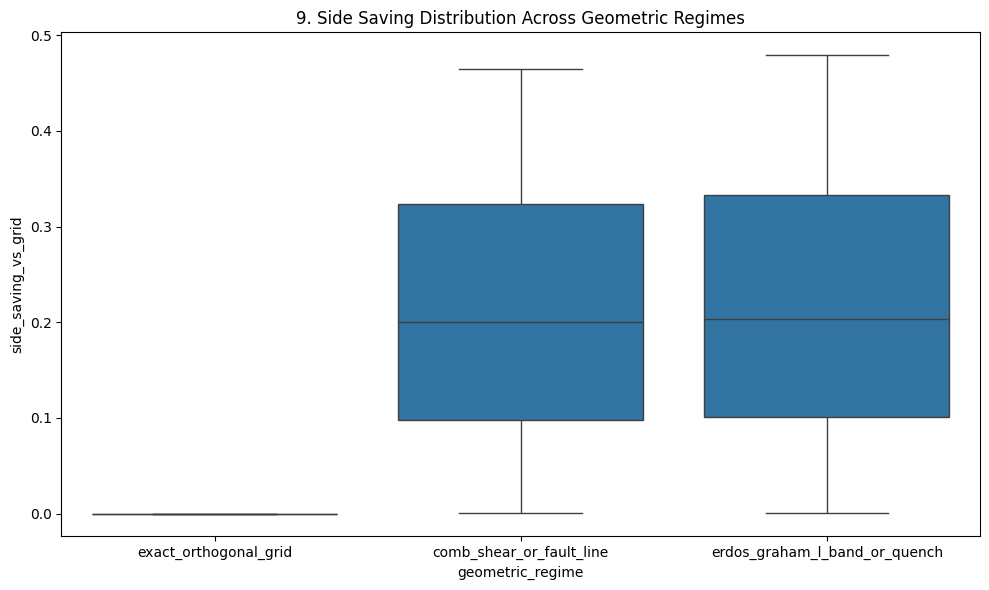

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='geometric_regime', y='side_saving_vs_grid')
plt.title(f'{plot_no}. Side Saving Distribution Across Geometric Regimes')
show_fig()
plot_no += 1

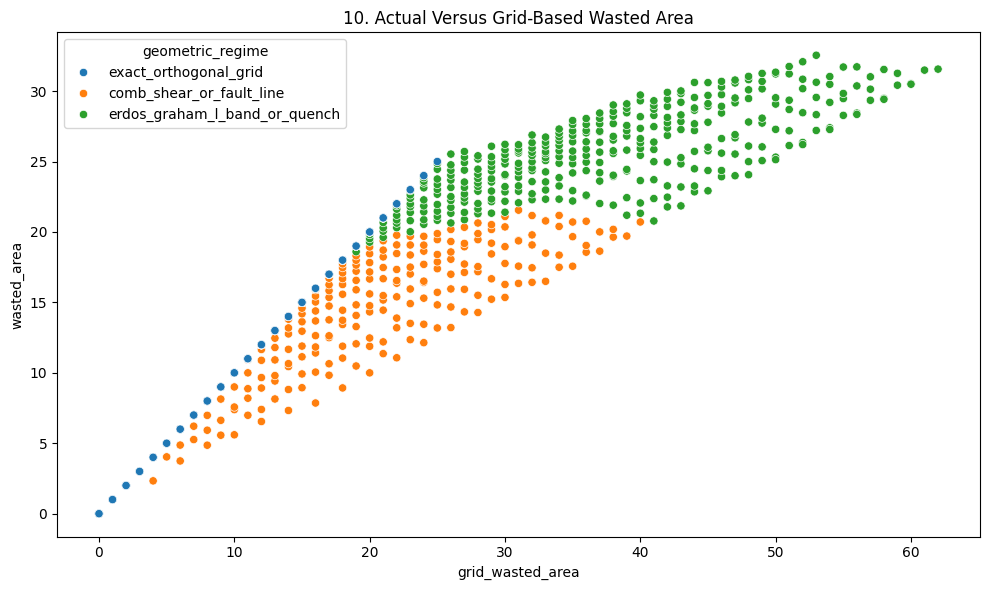

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='grid_wasted_area', y='wasted_area', hue='geometric_regime')
plt.title(f'{plot_no}. Actual Versus Grid-Based Wasted Area')
show_fig()
plot_no += 1

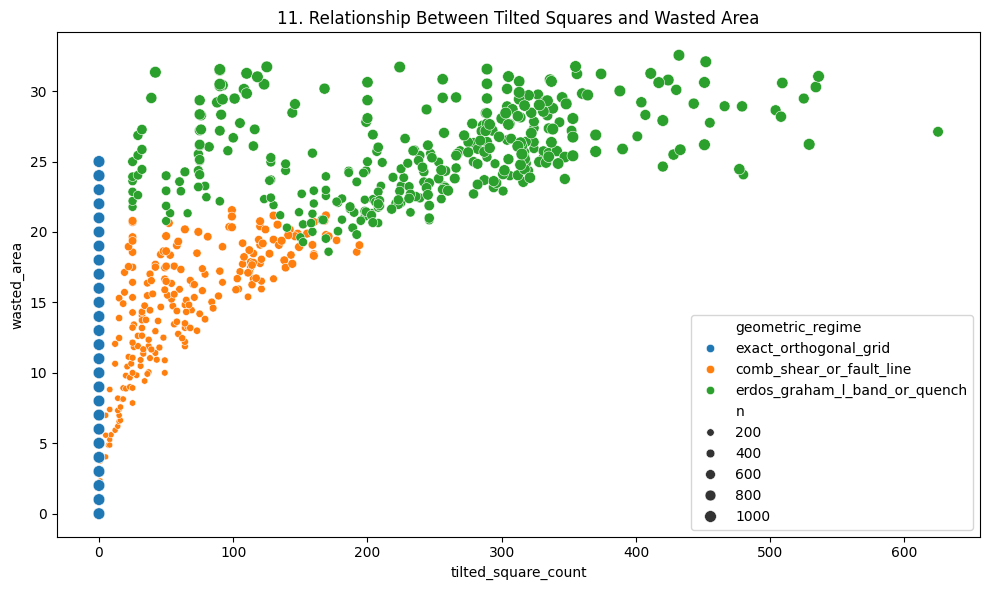

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='tilted_square_count', y='wasted_area', hue='geometric_regime', size='n')
plt.title(f'{plot_no}. Relationship Between Tilted Squares and Wasted Area')
show_fig()
plot_no += 1

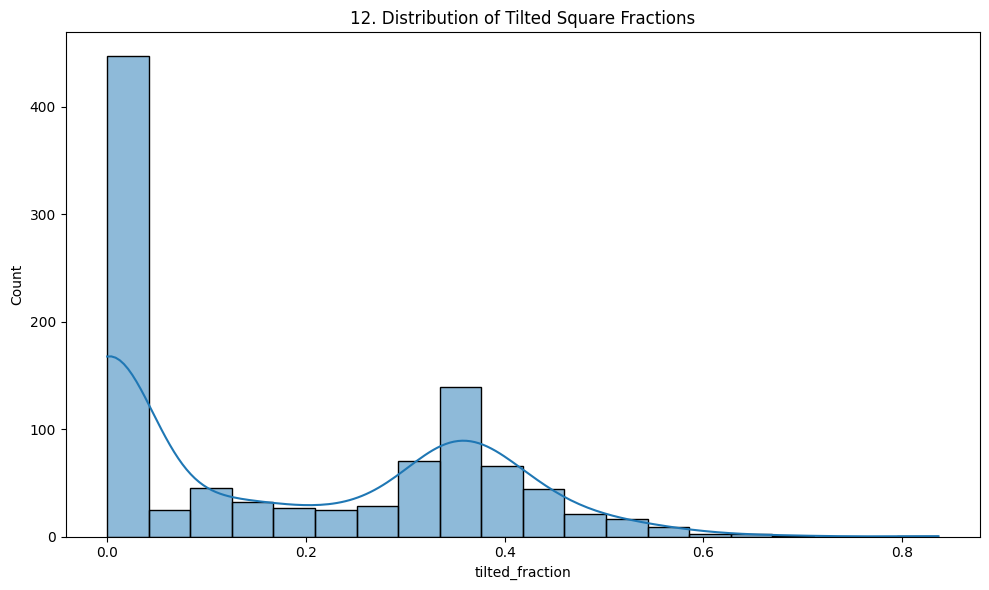

In [25]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='tilted_fraction', bins=20, kde=True)
plt.title(f'{plot_no}. Distribution of Tilted Square Fractions')
show_fig()
plot_no += 1

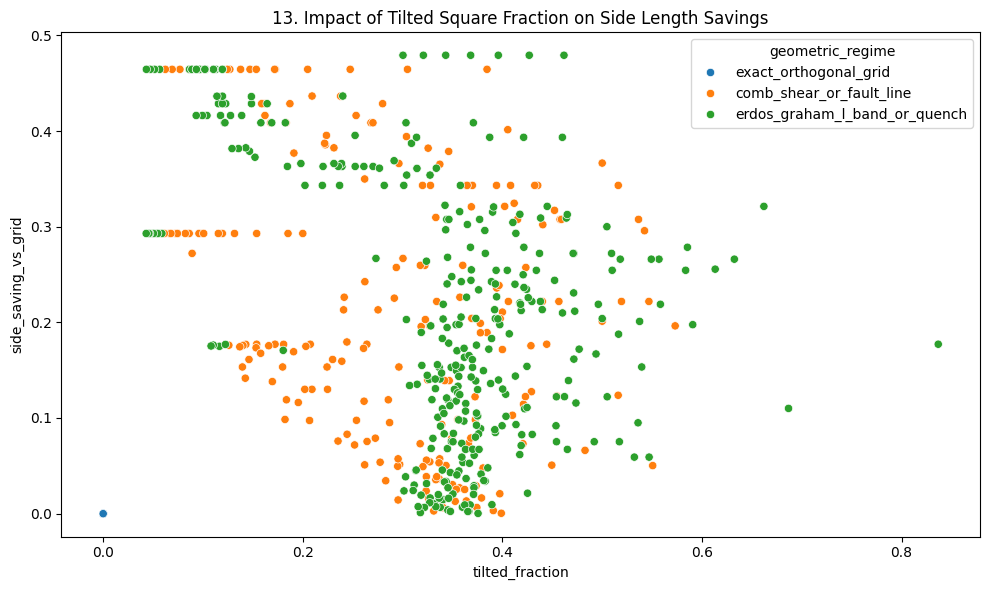

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='tilted_fraction', y='side_saving_vs_grid', hue='geometric_regime')
plt.title(f'{plot_no}. Impact of Tilted Square Fraction on Side Length Savings')
show_fig()
plot_no += 1

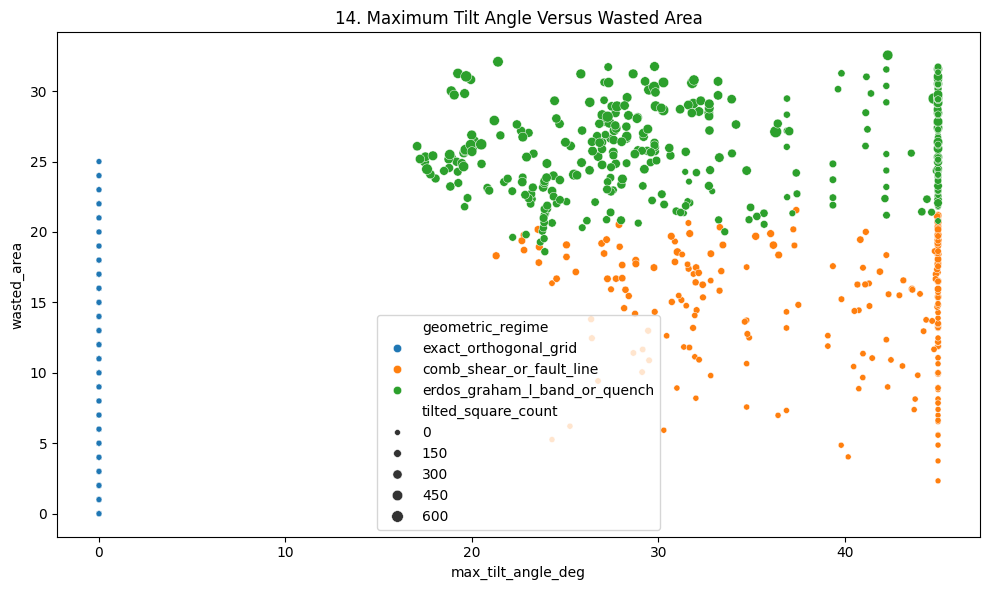

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='max_tilt_angle_deg', y='wasted_area', hue='geometric_regime', size='tilted_square_count')
plt.title(f'{plot_no}. Maximum Tilt Angle Versus Wasted Area')
show_fig()
plot_no += 1

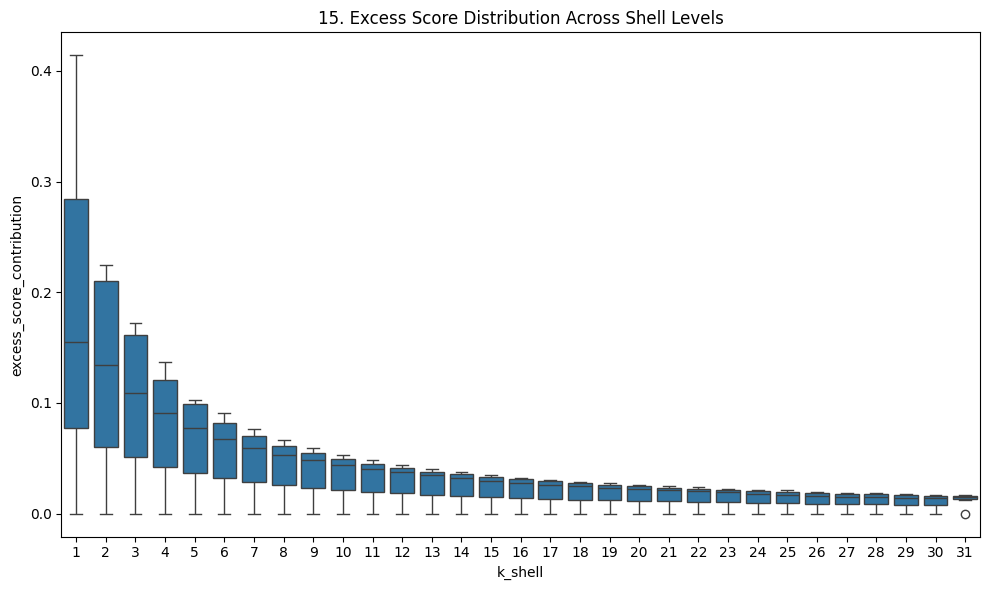

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='k_shell', y='excess_score_contribution')
plt.title(f'{plot_no}. Excess Score Distribution Across Shell Levels')
show_fig()
plot_no += 1

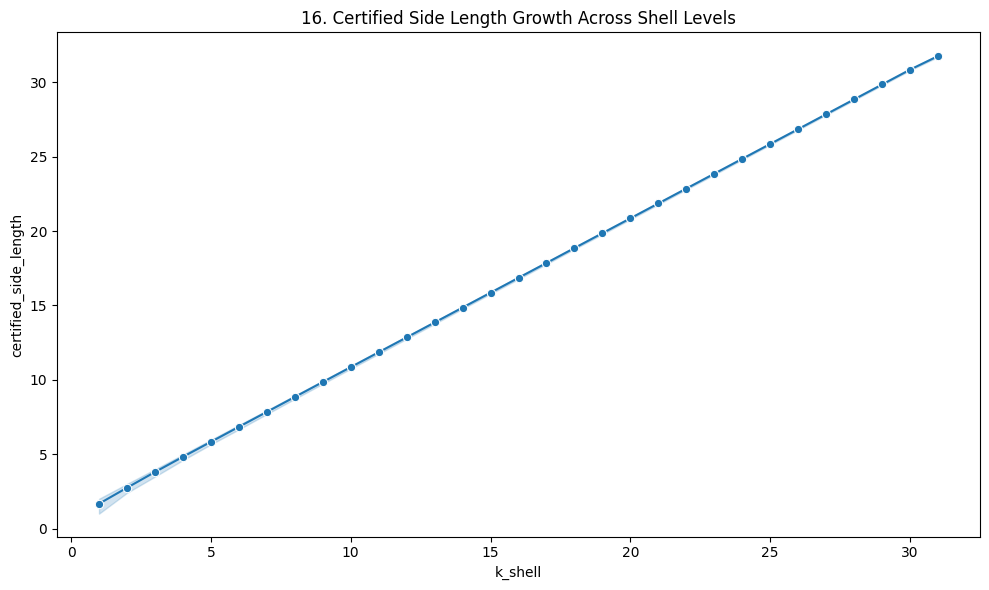

In [29]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='k_shell', y='certified_side_length', marker='o')
plt.title(f'{plot_no}. Certified Side Length Growth Across Shell Levels')
show_fig()
plot_no += 1

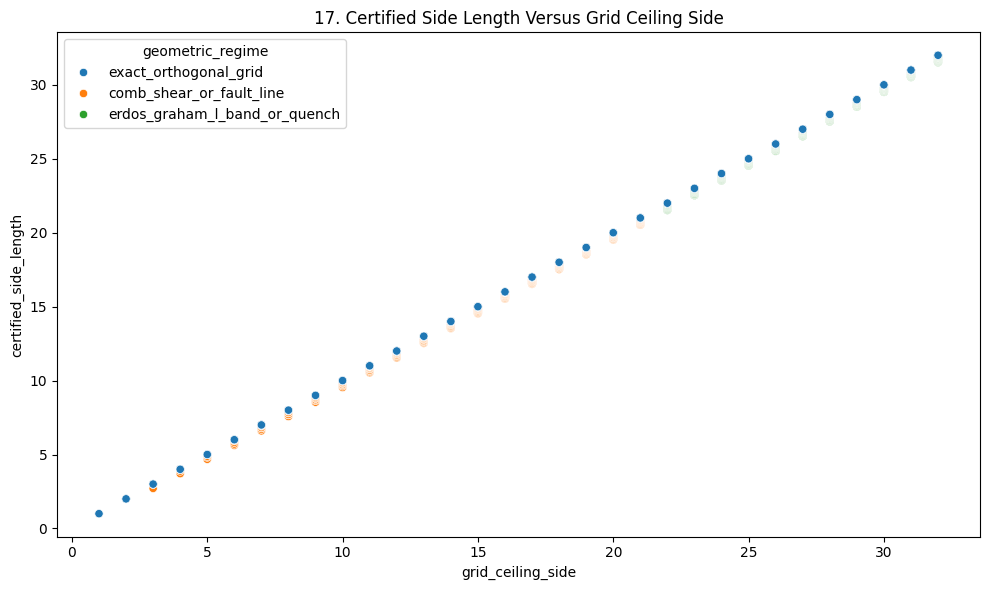

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='grid_ceiling_side', y='certified_side_length', hue='geometric_regime')
plt.title(f'{plot_no}. Certified Side Length Versus Grid Ceiling Side')
show_fig()
plot_no += 1

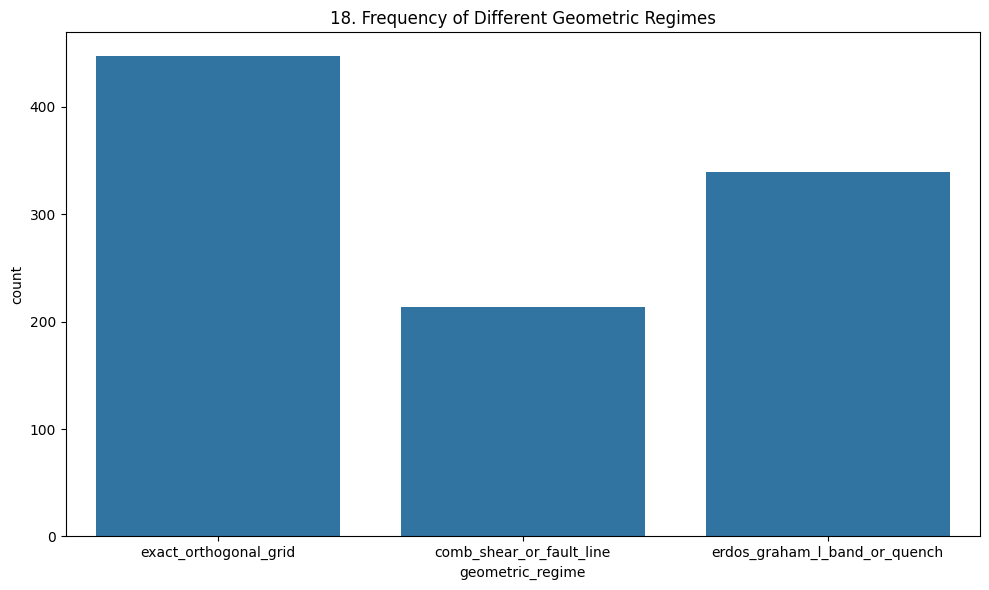

In [31]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='geometric_regime')
plt.title(f'{plot_no}. Frequency of Different Geometric Regimes')
show_fig()
plot_no += 1

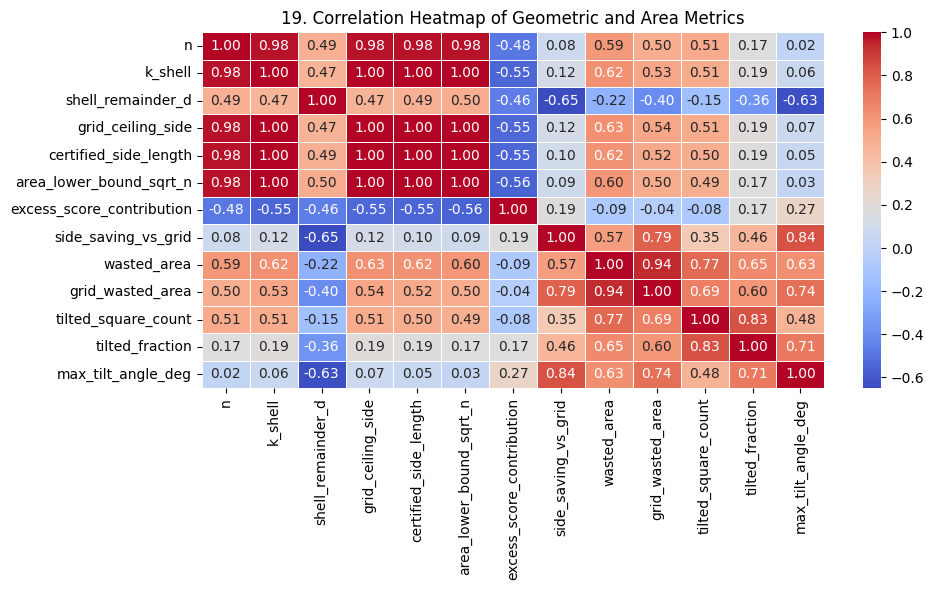

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Geometric and Area Metrics')
show_fig()
plot_no += 1

# Model Training

## Prepare dataset

In [33]:
target = 'certified_side_length'

X = df.drop(columns=[target, 'geometric_regime'], errors='ignore')
y = df[target]

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess features

In [35]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

## Split dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Build regression pipeline

In [37]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingRegressor(random_state=42))
])

## Tune hyperparameters

In [38]:
params = {
    'model__max_iter': [100, 200, 300, 500],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_leaf_nodes': [15, 20, 31, 40],
    'model__l2_regularization': [0, 0.1, 1, 5],
    'model__min_samples_leaf': [5, 10, 15, 20]
}

search = RandomizedSearchCV(
    pipeline,
    params,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

## Train the best model

In [39]:
search.fit(X_train, y_train)
model = search.best_estimator_

## Make predictions

In [40]:
y_pred = model.predict(X_test)

## Evaluate model

In [41]:
print("Best Parameters:", search.best_params_)
print("R2 Accuracy:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

Best Parameters: {'model__min_samples_leaf': 5, 'model__max_leaf_nodes': 40, 'model__max_iter': 500, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
R2 Accuracy: 0.9998
MAE: 0.032
RMSE: 0.0994


## Plot actual vs predicted values

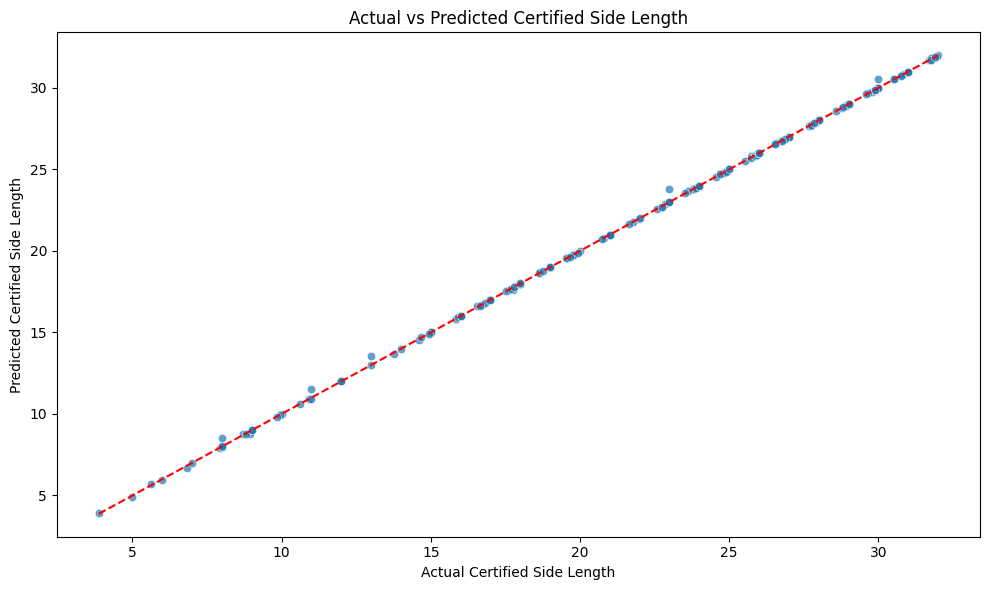

In [42]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    color='red'
)
plt.xlabel('Actual Certified Side Length')
plt.ylabel('Predicted Certified Side Length')
plt.title('Actual vs Predicted Certified Side Length')
show_fig()